<a href="https://colab.research.google.com/github/grmntfrancis0/earthengine-community/blob/main/NDVI_Timeseries_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install --upgrade --pre xee
!pip install -U geemap

In [2]:
import ee

In [3]:
ee.Authenticate()
ee.Initialize(
    project = "ee-grmntfrancis0",
    opt_url='https://earthengine-highvolume.googleapis.com'
)

In [8]:
forest = (
    ee.Image("UMD/hansen/global_forest_change_2025_v1_13")
    .select("loss", "lossyear")
)

loss_area = forest.select("loss").eq(1).And(
    forest.select("lossyear").eq(15)
)

In [12]:
import geemap

In [15]:
import geemap

In [16]:
map = geemap.Map(basemap = "SATELLITE")
map.addLayer(loss_area, {}, "Loss Area")
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [57]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          33.639198,
                          4.421031
                        ],
                        [
                          33.639198,
                          4.460395
                        ],
                        [
                          33.65534,
                          4.460395
                        ],
                        [
                          33.65534,
                          4.421031
                        ],
                        [
                          33.639198,
                          4.421031
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

MODIS NDVI Image Collection

In [58]:
modis = (ee.ImageCollection("MODIS/061/MOD13Q1")
    .filterDate("2000", "2026")
    .select("NDVI")

)
modis

# **Convert to Xarray**

In [59]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [60]:
grid_params = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = "EPSG:3857",
    grid_scale = (250, -250)
)

In [61]:
ds = xr.open_dataset(
    modis,
    engine = "ee",
    **grid_params
)

ds = ds.sortby("time")*0.0001

# **NDVI Time Series**

In [62]:
ds_mean = ds["NDVI"].mean(dim = ["x", "y"])
ds_mean.to_dataframe()

,NDVI
time,
2000-02-18,0.333970
2000-03-05,0.368696
2000-03-21,0.351507
2000-04-06,0.436349
2000-04-22,0.591318
...,...
2025-10-16,0.788669
2025-11-01,0.780480
2025-11-17,0.728213


In [63]:
import matplotlib.pyplot as plt

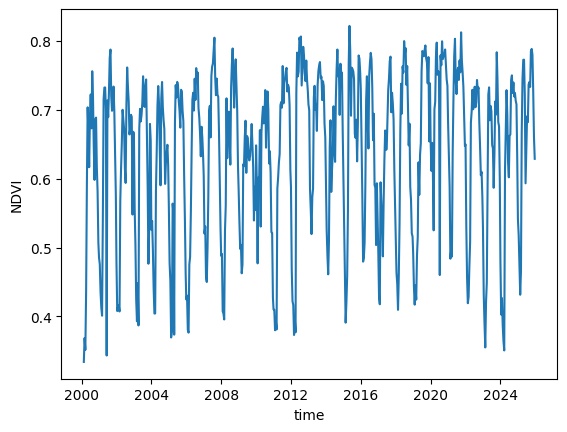

In [64]:
ds_mean.plot()

Trend Analysis

In [65]:
from statsmodels.tsa.seasonal import STL

In [66]:
stl_model = STL(ds_mean, period = 24)
stl_result = stl_model.fit()

In [67]:
ndvi_trend = stl_result.trend


<Axes: title={'center': 'NDVI Trend over Time'}, xlabel='Time', ylabel='NDVI'>

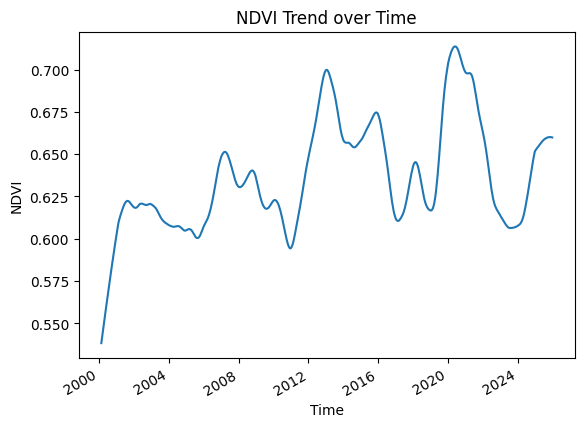

In [68]:
import pandas as pd
# Convert the numpy array to a pandas Series with the time index
ndvi_trend_series = pd.Series(ndvi_trend, index=ds_mean.time.values)
ndvi_trend_series.plot(title="NDVI Trend over Time", ylabel="NDVI", xlabel="Time")

In [69]:
!pip install pymannkendall
!pip install pyhomogeneity
import pymannkendall as mk
import pyhomogeneity as hg

In [70]:
mk_test = mk.original_test(ndvi_trend)
hg_test = hg.pettitt_test(ndvi_trend)
print(mk_test)
print(hg_test)

Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.0), z=np.float64(11.126050135034147), Tau=np.float64(0.30498259910024617), s=np.float64(53895.0), var_s=23463825.0, slope=np.float64(8.421176947626382e-05), intercept=np.float64(0.6041253148847234))
Pettitt_Test(h=np.True_, cp=np.int64(266), p=np.float64(0.0), U=np.float64(59472.0), avg=mean(mu1=np.float64(0.6154217524797924), mu2=np.float64(0.6531949425646716)))
